In [572]:
%load_ext autoreload
%autoreload 2
import os
import math,random
import numpy as np
import torch
import draw,utils
import warnings
import matplotlib.pyplot as plt
import torch.nn as nn

warnings.filterwarnings("ignore")

def Vis_Rgt_Curves(data, curves_num=10, width=2):
    rgt_min,rgt_max = np.min(data), np.max(data)
    xx = np.linspace(rgt_max,rgt_min,curves_num)
    rgt_line = np.zeros(data.shape)
    rgt_line = np.full(data.shape,np.nan)
    for j in range(data.shape[1]):
        for ni in range(curves_num):
            xi_arg = np.argmin(np.abs(data[:,j]-xx[ni]))
            xi_1,xi_2 = np.max((0,xi_arg-width)), np.min((data.shape[0]-width,xi_arg+1))
            rgt_line[xi_1:xi_2, j] = xx[ni]
    return rgt_line

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [573]:
datanum = 1247
Modelname = "RLHF_base_onedata_lora_horizon"

In [574]:
root_path = os.path.abspath(".")
dataset_name = 'dataset'
dataset_path = os.path.join(root_path, dataset_name)
train_sample_path = os.path.join(dataset_path, "field2d_512_horizon")
samples_train = np.array([str(datanum)])
print(f"训练实际样本数量: {len(samples_train)}")
input_attr_list = ["seis"]
rgt_attr_list = ["rgt"]
fault_attr_list = ["fault"]
prior_attr_list1 = ["segment"]
prior_attr_list2 = ["normal"]
prior_attr_list3 = ["horizon"]

训练实际样本数量: 1


In [575]:
os.environ['CUDA_VISIBLE_DEVICES']= '0'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    num_GPU = torch.cuda.device_count()
    print(f"GPU 数量: {num_GPU}")
print(f"运行平台: {device}")
root_path = os.path.abspath('.')

GPU 数量: 1
运行平台: cuda


In [576]:
train_data =  utils.build_dataset_lora(samples_train, train_sample_path, 'Train',
                                           input_attr_list = input_attr_list,
                                           prior_attr_list1 = prior_attr_list1,
                                           prior_attr_list2 = prior_attr_list2,
                                           prior_attr_list3 = prior_attr_list3,
                                           output_attr_list = rgt_attr_list, 
                                           output_attr_list2 = fault_attr_list)

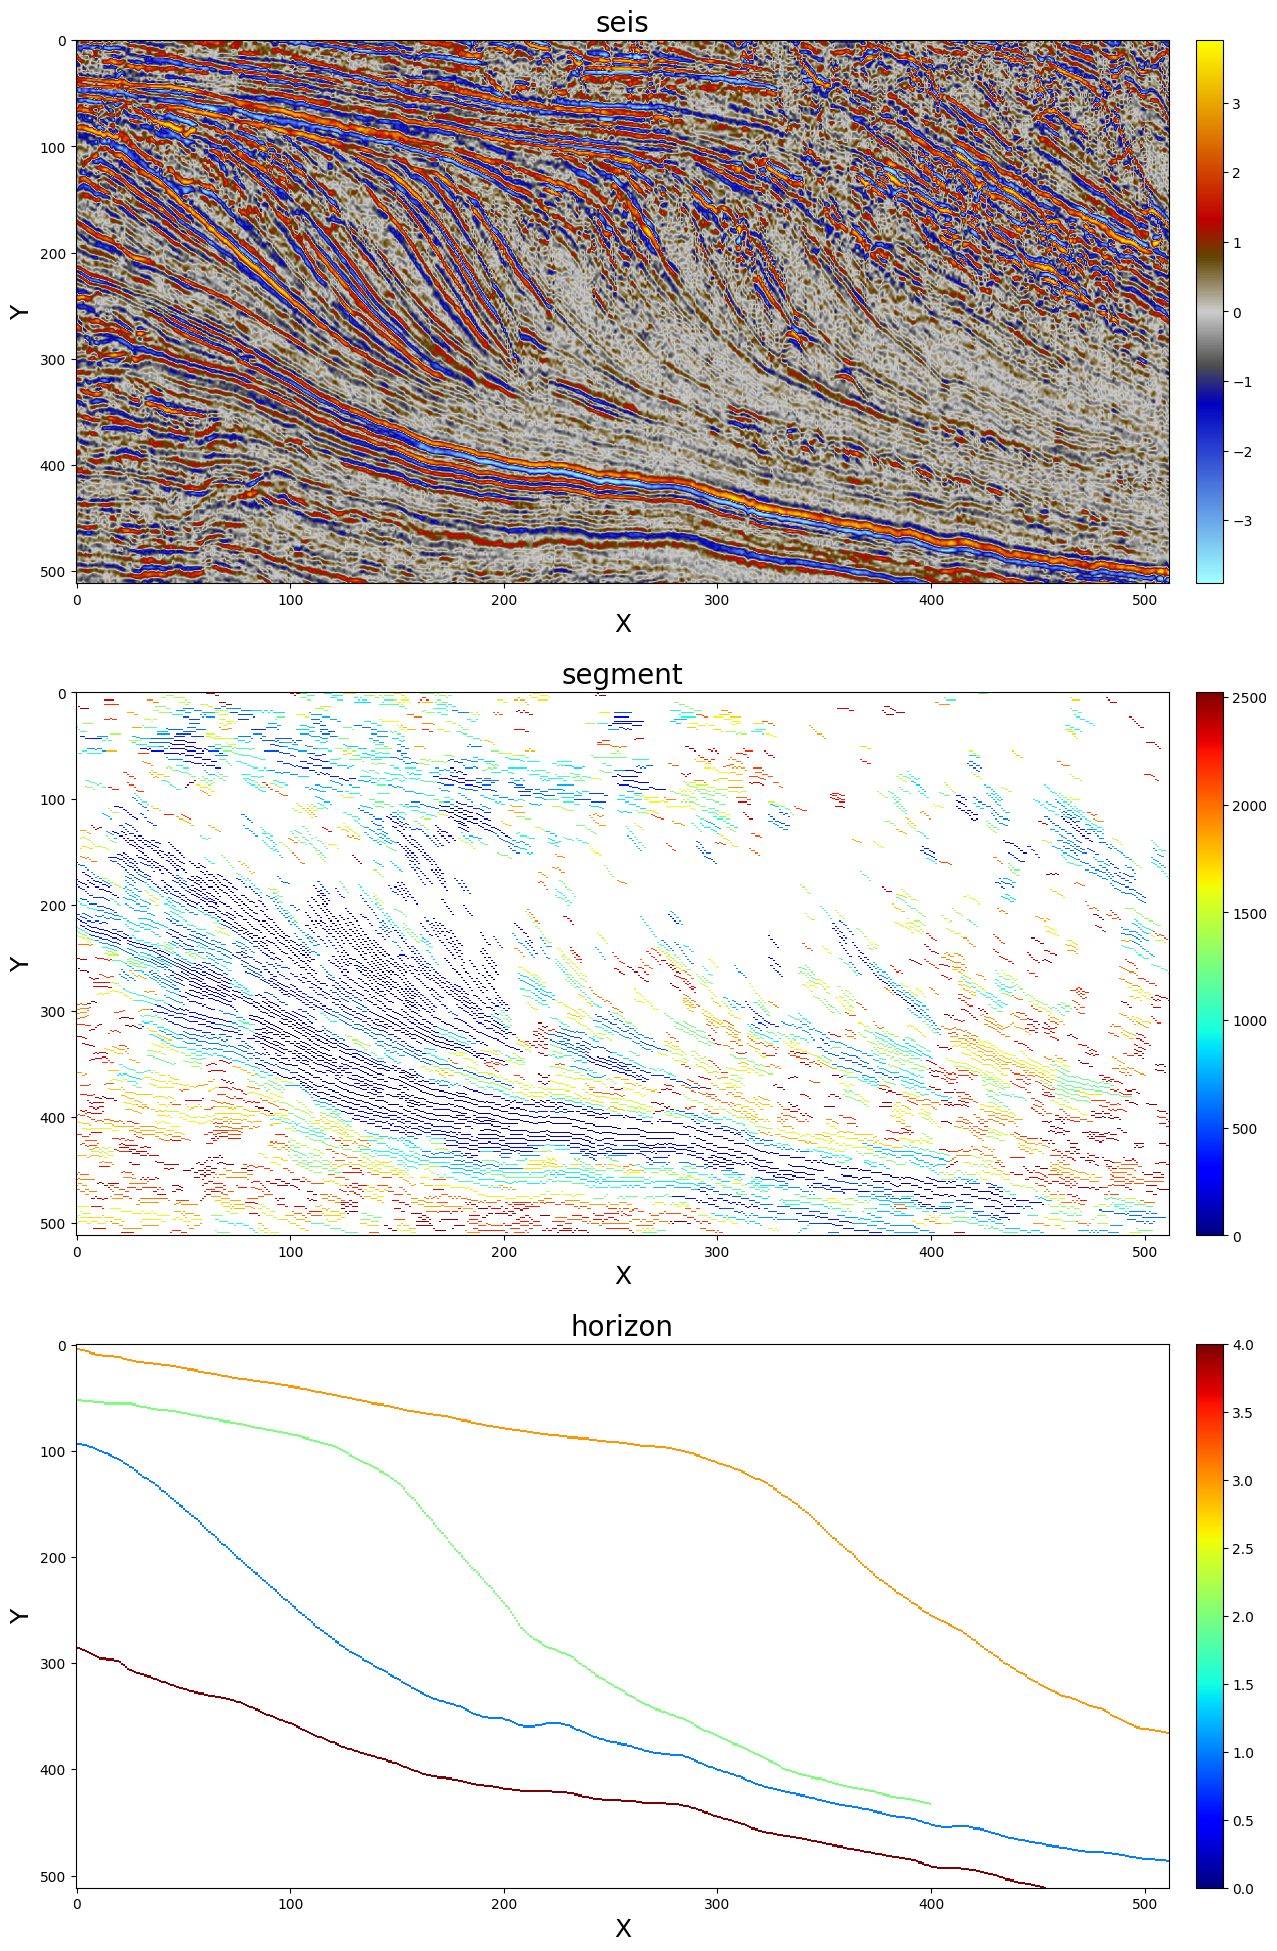

In [577]:
# plot
idxs = np.random.randint(0, len(train_data), size=1) 
batch_samples = [train_data[i] for i in idxs]
draw_attr_list = input_attr_list +  prior_attr_list1 + prior_attr_list3
draw.draw_samples(batch_samples, draw_attr_list, 
                  cmap=[utils.getPetrelColors(),
                        utils.setAlpha("jet",FillExceptMin=True),utils.setAlpha("jet",FillExceptMin=True)],
                  methods=["bilinear","nearest","nearest"])

In [590]:
import SFM_pretrain.model_rgt as models_rgt
import loralib as lora

model = models_rgt.vit_base_patch16(img_size=512, in_chans=1, num_classes=1, drop_path_rate=0.1)
# state_dict = torch.load("./checkpoints/Supervised_syn2d_base_step2/checkpoint-best.pth")['state_dict']
state_dict = torch.load("./checkpoints/Supervised_syn2d_base_step2_200epoch/checkpoint-best.pth")['state_dict']
new_state_dict = {k.replace('module.', ''): v for k, v in state_dict.items()} # 移除module.前缀
model.load_state_dict(new_state_dict)

utils.inject_lora_vit(model, r=8, alpha=16) # 插入lora,确保并行分支参数读入，而非随机参数
# lora_state_dict = torch.load("./checkpoints/RLHF_fieldsyn2d_base_step2/checkpoint-best.pth")['state_dict']
lora_state_dict = torch.load("./checkpoints/RLHF_fieldsyn2d_base_step2_200epoch/checkpoint-best.pth")['state_dict']
new_lora_state_dict = {k.replace('module.', ''): v for k, v in lora_state_dict.items()} # 移除module.前缀
model.load_state_dict(lora_state_dict,strict=False)

for name, p in model.named_parameters():
#     if "lora_" in name or "decoder" in name or "segmentation_head" in name:
    if "lora_" in name:
        p.requires_grad = True
    else:
        p.requires_grad = False
        
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
trainable_params_ratio = trainable_params / total_params * 100
print(f"Total parameters: {total_params},\nTrainable parameters: {trainable_params},\nTrainable parameters ratio: {trainable_params_ratio:.2f}%")

# 并行模式
if torch.cuda.is_available():
    model = torch.nn.DataParallel(model, device_ids=range(num_GPU)).to(device)
else:
    model = model.to(device)

checkpoint_path = os.path.join('checkpoints', Modelname)
if not os.path.exists(checkpoint_path):
    os.makedirs(checkpoint_path)
print(f"模型读取路径: {checkpoint_path}")

Total parameters: 89491362,
Trainable parameters: 442368,
Trainable parameters ratio: 0.49%
模型读取路径: checkpoints/RLHF_base_onedata_lora_horizon


In [591]:
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.optim as optim
from torch.autograd import Variable
from torch.optim.lr_scheduler import StepLR, ReduceLROnPlateau
from torch.utils.data import Dataset, DataLoader
from priorloss import SegmentLoss,NormalLoss

train_loader = DataLoader(dataset=train_data, batch_size=1, shuffle=False, drop_last=True)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=0)
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.5)

criterion1 = SegmentLoss().to(device)
criterion2 = NormalLoss().to(device)
criterion3 = SegmentLoss().to(device)

best_mse = 1e50
for epoch in range(200):
    model.train()
    for batch_idx, batch_samples in enumerate(train_loader):
        data = batch_samples["seis"].to(torch.float32).unsqueeze(1)
        data = Variable(data.to(device)) # seismic data [bs,channel,X,Y]

        segment = batch_samples["segment"].to(torch.float32)
        segment = Variable(segment.to(device)) # segment label [bs,channel,X,Y]
        normal = batch_samples["normal"].to(torch.float32)
        normal = Variable(normal.to(device)) # normal label [bs,channel,X,Y,2]
        horizon = batch_samples["horizon"].to(torch.float32)
        horizon = Variable(horizon.to(device)) # horizon label [bs,channel,X,Y]
        
        optimizer.zero_grad()
        pred = model(data)
        loss1 = 10*criterion1(pred, segment)
        loss2 = criterion2(pred, normal)
        loss3 = 40*criterion3(pred, horizon)
        loss = loss1 + loss2 + loss3
#         loss = loss1 + loss3
        loss.backward()
        optimizer.step()
        
        scheduler.step(loss)
        
        if loss < best_mse:
            state = {'epoch': epoch, 'state_dict': lora.lora_state_dict(model), 'optimizer': optimizer.state_dict()}
            filename = os.path.join(checkpoint_path, 'lora'+str(datanum)+'.pth')
            torch.save(state, filename)
            best_mse = loss
        print('Epoch:{}, Loss:{:.5f} <{:.4f} & {:.4f} & {:.4f}>, Learning rate: {:.8f}'.format(epoch, loss,loss1,loss2,loss3,optimizer.param_groups[0]['lr']))

Epoch:0, Loss:21.96169 <0.1779 & 0.0967 & 21.6871>, Learning rate: 0.00100000
Epoch:1, Loss:21.28748 <0.1752 & 0.0958 & 21.0164>, Learning rate: 0.00100000
Epoch:2, Loss:20.15071 <0.1697 & 0.0933 & 19.8877>, Learning rate: 0.00100000
Epoch:3, Loss:18.88983 <0.1669 & 0.0935 & 18.6295>, Learning rate: 0.00100000
Epoch:4, Loss:17.70060 <0.1701 & 0.0938 & 17.4368>, Learning rate: 0.00100000
Epoch:5, Loss:15.49589 <0.1645 & 0.0908 & 15.2406>, Learning rate: 0.00100000
Epoch:6, Loss:14.85258 <0.1767 & 0.0928 & 14.5830>, Learning rate: 0.00100000
Epoch:7, Loss:15.04146 <0.1823 & 0.0922 & 14.7669>, Learning rate: 0.00100000
Epoch:8, Loss:14.88053 <0.1988 & 0.0968 & 14.5849>, Learning rate: 0.00100000
Epoch:9, Loss:14.01480 <0.2077 & 0.0991 & 13.7080>, Learning rate: 0.00100000
Epoch:10, Loss:13.26427 <0.2133 & 0.1030 & 12.9480>, Learning rate: 0.00100000
Epoch:11, Loss:12.60803 <0.2062 & 0.1043 & 12.2976>, Learning rate: 0.00100000
Epoch:12, Loss:14.28116 <0.1816 & 0.0988 & 14.0008>, Learning 

Epoch:108, Loss:7.01432 <0.1615 & 0.0905 & 6.7623>, Learning rate: 0.00000003
Epoch:109, Loss:4.76669 <0.1545 & 0.1019 & 4.5103>, Learning rate: 0.00000003
Epoch:110, Loss:3.76671 <0.1545 & 0.1034 & 3.5088>, Learning rate: 0.00000002
Epoch:111, Loss:4.40332 <0.1574 & 0.1033 & 4.1426>, Learning rate: 0.00000002
Epoch:112, Loss:3.79409 <0.1570 & 0.1057 & 3.5314>, Learning rate: 0.00000002
Epoch:113, Loss:5.00076 <0.1527 & 0.0984 & 4.7496>, Learning rate: 0.00000002
Epoch:114, Loss:3.76670 <0.1545 & 0.1034 & 3.5087>, Learning rate: 0.00000002
Epoch:115, Loss:4.00703 <0.1539 & 0.1007 & 3.7525>, Learning rate: 0.00000002
Epoch:116, Loss:4.14544 <0.1513 & 0.0994 & 3.8947>, Learning rate: 0.00000002
Epoch:117, Loss:3.76669 <0.1545 & 0.1034 & 3.5087>, Learning rate: 0.00000002
Epoch:118, Loss:3.76667 <0.1545 & 0.1034 & 3.5087>, Learning rate: 0.00000002
Epoch:119, Loss:5.11052 <0.1644 & 0.1046 & 4.8415>, Learning rate: 0.00000002
Epoch:120, Loss:3.81400 <0.1536 & 0.1009 & 3.5596>, Learning rat

In [797]:

datanum = 2974

In [799]:
import SFM_pretrain.model_rgt as models_rgt
import loralib as lora

model0 = models_rgt.vit_base_patch16(img_size=512, in_chans=1, num_classes=1, drop_path_rate=0.1)
state_dict0 = torch.load("./checkpoints/Supervised_syn2d_base_step2_200epoch/checkpoint-best.pth")['state_dict']
new_state_dict0 = {k.replace('module.', ''): v for k, v in state_dict0.items()} # 移除module.前缀
model0.load_state_dict(new_state_dict0)
utils.inject_lora_vit(model0, r=8, alpha=16) # 插入lora,确保并行分支参数读入，而非随机参数
lora_state_dict0 = torch.load("./checkpoints/RLHF_base_onedata_lora/lora"+str(datanum)+".pth")['state_dict']
new_lora_state_dict0 = {k.replace('module.', ''): v for k, v in lora_state_dict0.items()} # 移除module.前缀
model0.load_state_dict(new_lora_state_dict0,strict=False)

model1 = models_rgt.vit_base_patch16(img_size=512, in_chans=1, num_classes=1, drop_path_rate=0.1)
state_dict1 = torch.load("./checkpoints/Supervised_syn2d_base_step2_200epoch/checkpoint-best.pth")['state_dict']
new_state_dict1 = {k.replace('module.', ''): v for k, v in state_dict1.items()} # 移除module.前缀
model1.load_state_dict(new_state_dict1)
utils.inject_lora_vit(model1, r=8, alpha=16) # 插入lora,确保并行分支参数读入，而非随机参数
# lora_state_dict1 = torch.load("./checkpoints/RLHF_base_onedata_lora_horizon/lora"+str(datanum)+".pth")['state_dict']
lora_state_dict1 = torch.load("./checkpoints/RLHF_base_onedata_lora_horizon/lora"+str(1108)+".pth")['state_dict']
new_lora_state_dict1 = {k.replace('module.', ''): v for k, v in lora_state_dict1.items()} # 移除module.前缀
model1.load_state_dict(new_lora_state_dict1,strict=False)

# 并行模式
if torch.cuda.is_available():
    model0 = torch.nn.DataParallel(model0, device_ids=range(num_GPU)).to(device)
    model1 = torch.nn.DataParallel(model1, device_ids=range(num_GPU)).to(device)
else:
    model0 = model0.to(device)
    model1 = model1.to(device)

In [800]:
seis = np.load("./dataset/field2d_512_segment/"+str(datanum)+".npy",allow_pickle=True).item()["seis"]
segment = np.load("./dataset/field2d_512_segment/"+str(datanum)+".npy",allow_pickle=True).item()["segment"]
# seis = np.load("./dataset/syn2d_512/30.npy",allow_pickle=True).item()["seis"]
seis = torch.from_numpy(seis).unsqueeze(0).unsqueeze(0).to(torch.float32).to(device)
# seis = torch.randn(1, 1, 512, 512)  # batch=1, 单通道, 512×512
pred0 = model0(seis)
pred1 = model1(seis)

In [801]:
# criterion3(pred1, horizon)*20

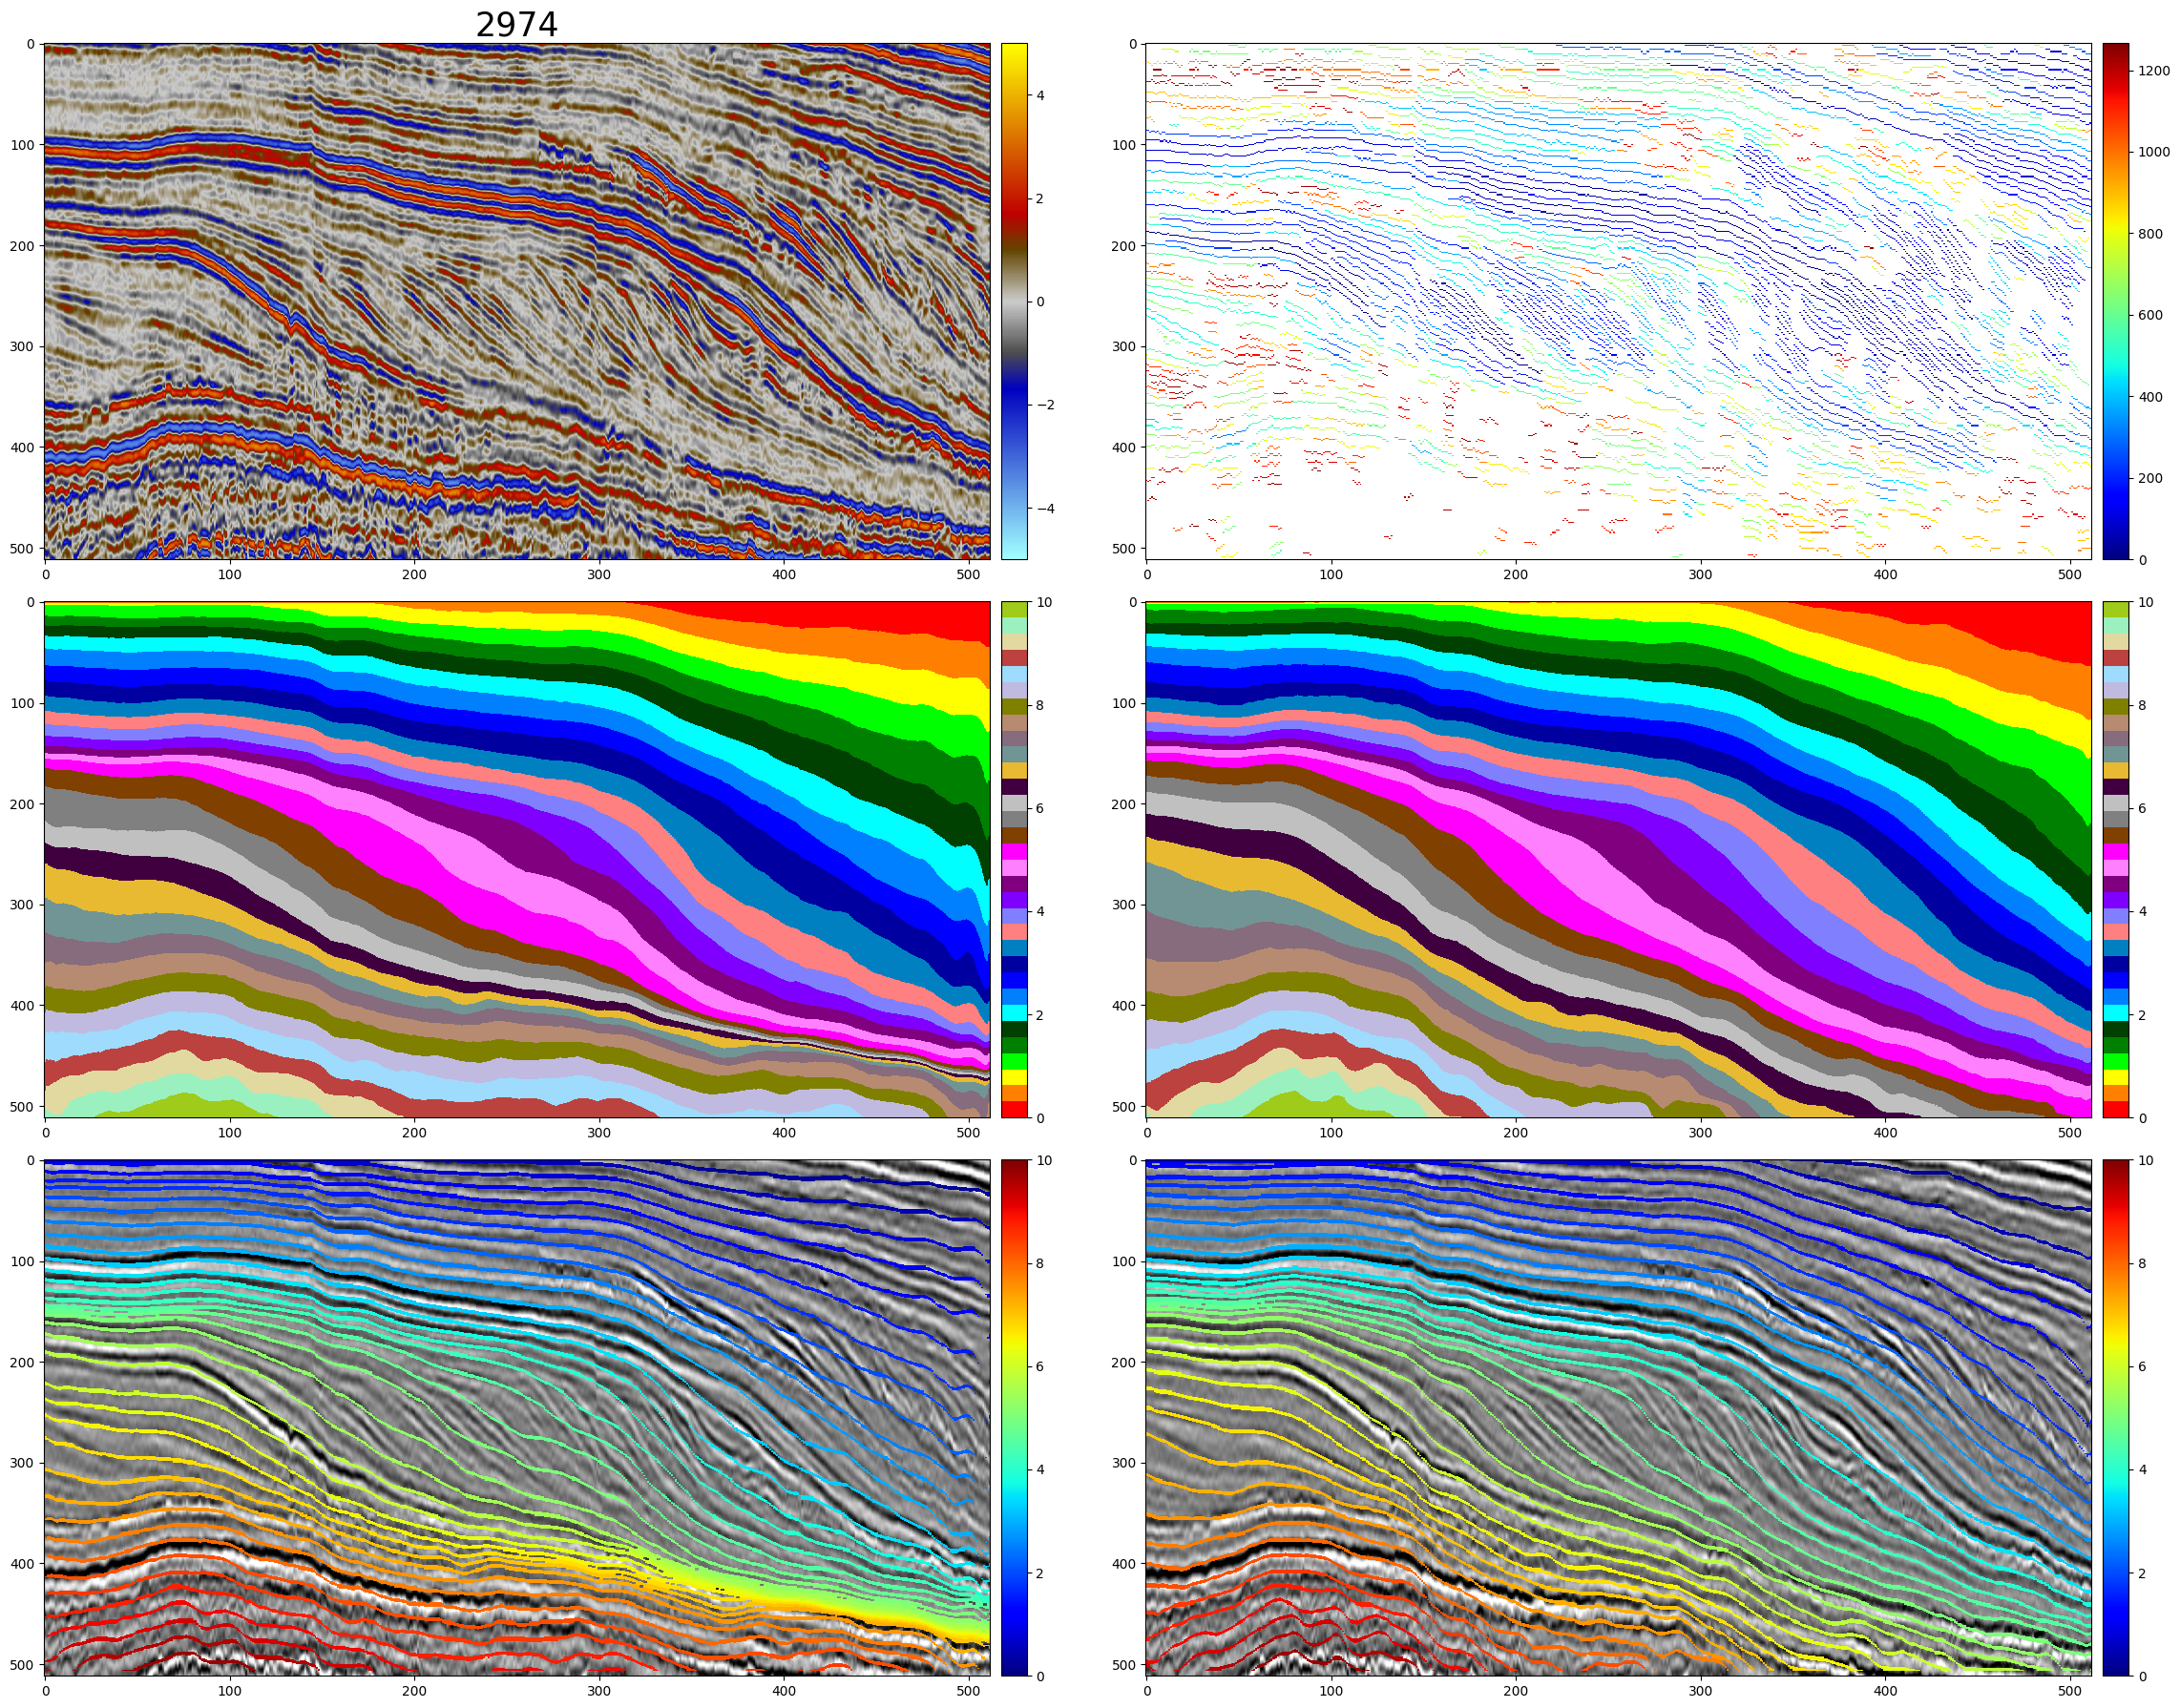

In [802]:
d1 = seis.squeeze().cpu().detach().numpy()
d2_0 = pred0.squeeze().cpu().detach().numpy()
d2_1 = pred1.squeeze().cpu().detach().numpy()

plt.figure(figsize=(24,18))
plt.subplot(3,2,1)
plt.imshow(d1,cmap=utils.getPetrelColors(),vmin=-5,vmax=5,aspect="auto")
plt.title(str(datanum),fontsize=25)
plt.colorbar(pad=0.01)

plt.subplot(3,2,3)
plt.imshow(d2_1,cmap=utils.getStrataColors(),aspect="auto")
plt.colorbar(pad=0.01)

plt.subplot(3,2,5)
curves = Vis_Rgt_Curves(d2_1,curves_num=41,width=4)
plt.imshow(d1,cmap="gray",vmin=-3,vmax=3,aspect="auto")
plt.imshow(curves,cmap="jet",aspect="auto")
plt.colorbar(pad=0.01)

plt.subplot(3,2,4)
plt.imshow(d2_0,cmap=utils.getStrataColors(),aspect="auto")
plt.colorbar(pad=0.01)

plt.subplot(3,2,6)
curves = Vis_Rgt_Curves(d2_0,curves_num=41,width=4)
plt.imshow(d1,cmap="gray",vmin=-3,vmax=3,aspect="auto")
plt.imshow(curves,cmap="jet",aspect="auto")
plt.colorbar(pad=0.01)

plt.subplot(3,2,2)
plt.imshow(segment,cmap=utils.setAlpha("jet",FillExceptMin=True),interpolation="nearest",aspect="auto")
plt.colorbar(pad=0.01)

plt.tight_layout()